In [6]:
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np 
import json
from datetime import datetime, timezone
from pathlib import Path

from catalogo import (
    leer_satelites,
    anio_lanzamiento,
    grupo,
    lanzamientos_por_anio,
    contar_por_grupo
)
from satelite import (
    Satelite,
    crear_satelites
)
from analisis import resumen_por_grupo
from funciones_base import epoch_medio

 



In [7]:
ruta_datos = RUTA_PROYECTO / "datos" / "satelites.json"

registros = leer_satelites(ruta_datos)

print("Cantidad de registros:", len(registros))

Cantidad de registros: 16822


In [8]:
lanzamientos = lanzamientos_por_anio(registros)

print(lanzamientos)

{1964: 2, 1965: 3, 1967: 4, 1971: 1, 1974: 1, 1975: 1, 1976: 1, 1983: 1, 1984: 1, 1986: 1, 1988: 1, 1989: 3, 1990: 2, 1991: 1, 1992: 1, 1993: 6, 1994: 1, 1995: 3, 1996: 6, 1997: 4, 1998: 24, 1999: 8, 2000: 10, 2001: 11, 2002: 13, 2003: 25, 2004: 23, 2005: 19, 2006: 20, 2007: 37, 2008: 40, 2009: 51, 2010: 58, 2011: 62, 2012: 63, 2013: 96, 2014: 111, 2015: 96, 2016: 84, 2017: 136, 2018: 193, 2019: 144, 2020: 354, 2021: 987, 2022: 1715, 2023: 2260, 2024: 2428, 2025: 4289, 2026: 3421}


# Grafico de los lanzamientos de salelites por año

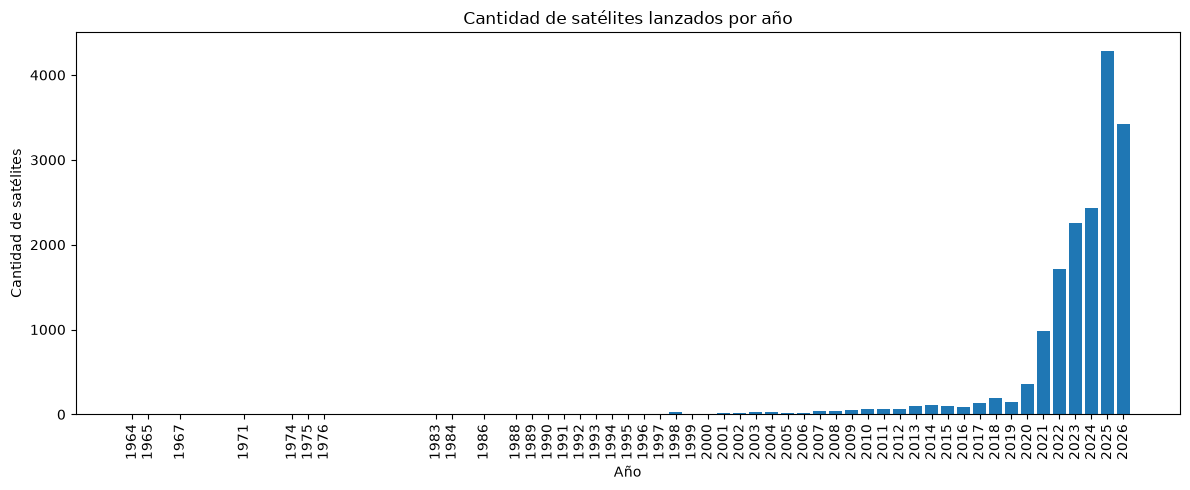

In [11]:
anios = sorted(lanzamientos.keys())
cantidades = [lanzamientos[anio] for anio in anios]

plt.figure(figsize=(12, 5))
plt.bar(anios, cantidades)

plt.title("Cantidad de satélites lanzados por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de satélites")

plt.xticks(anios, rotation=90)
plt.tight_layout()
plt.show()

# Registros de los satelites Arlink  

In [14]:
registros_starlink = [
    reg for reg in registros
    if grupo(reg["OBJECT_NAME"]) == "Starlink"
]

registros_resto = [
    reg for reg in registros
    if grupo(reg["OBJECT_NAME"]) != "Starlink"
] 

In [15]:
print("Satélites Starlink:", len(registros_starlink))
print("Resto de satélites:", len(registros_resto))

Satélites Starlink: 11160
Resto de satélites: 5662


# ¿Cuantos satelites Starlink y varios se registraron por año?
Creamos una funcion para graficar con azul: los satelites Starlink y los demas satelites que se lanzaron por año


In [16]:
def graficar_lanzamientos_apilados(diccionario1, diccionario2):

    anios = sorted(set(diccionario1) | set(diccionario2))

    valores1 = [diccionario1.get(anio, 0) for anio in anios]
    valores2 = [diccionario2.get(anio, 0) for anio in anios]

    plt.figure(figsize=(12, 5))

    plt.bar(anios, valores1, label="Starlink")
    plt.bar(anios, valores2, bottom=valores1, label="Resto")

    plt.title("Satélites lanzados por año: Starlink vs. resto")
    plt.xlabel("Año")
    plt.ylabel("Cantidad de satélites")

    plt.xticks(anios, rotation=90)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [18]:
lanzamientos_starlink = lanzamientos_por_anio(registros_starlink)
lanzamientos_resto = lanzamientos_por_anio(registros_resto)

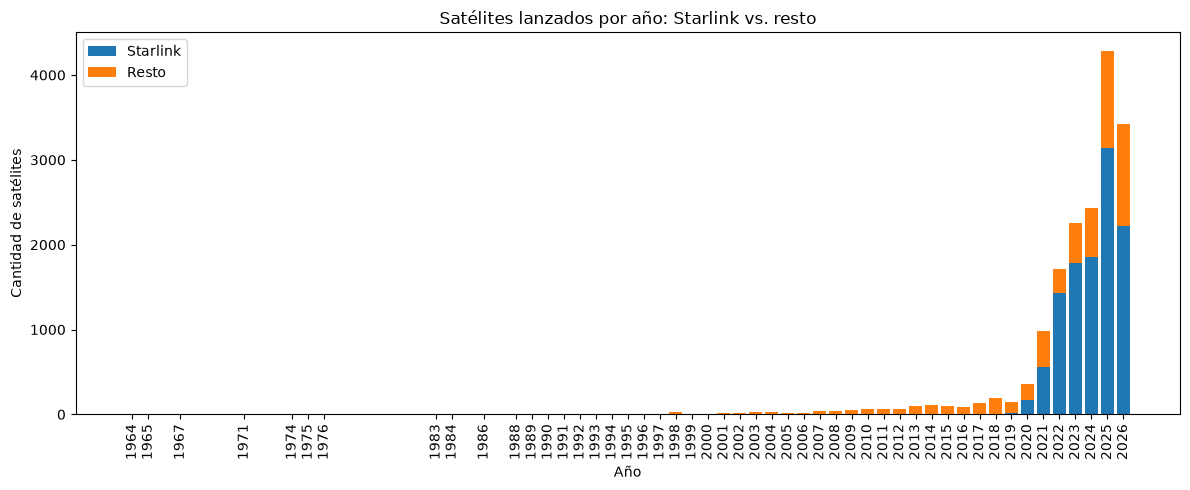

In [19]:
graficar_lanzamientos_apilados(
    lanzamientos_starlink,
    lanzamientos_resto
)